# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [2]:
derived_cols = ["ai_score", "ai_flag"]   # derived by ColdSense; the rest is measured or from the maintenance log
n_alerts = int((df["ai_flag"] == 1).sum())   # rows with an alert
fault_rate_pct = round(df["confirmed_fault"].mean() * 100, 2)   # base rate of real faults

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


,fault hours
fault_type,
compressor trip,10
defrost heater stuck,11
sensor frozen,25


**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*Your answer:*

**Visual channels:** `ai_score` is quantitative, so it should go on an aligned position axis (e.g. y-position in a strip plot or time series) or, as a second choice, a sequential lightness/size ramp, because people compare position and ordered magnitude accurately. `ai_flag` is binary/categorical, so a categorical channel such as hue or marker shape suits it. **What the flag throws away:** the strength of the evidence. A score of 0.51 and a score of 0.99 both become "1", so you lose the ranking, the near-misses just under 0.5, and the ability to choose a different threshold or scale the emphasis to confidence; the score keeps all of that.

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

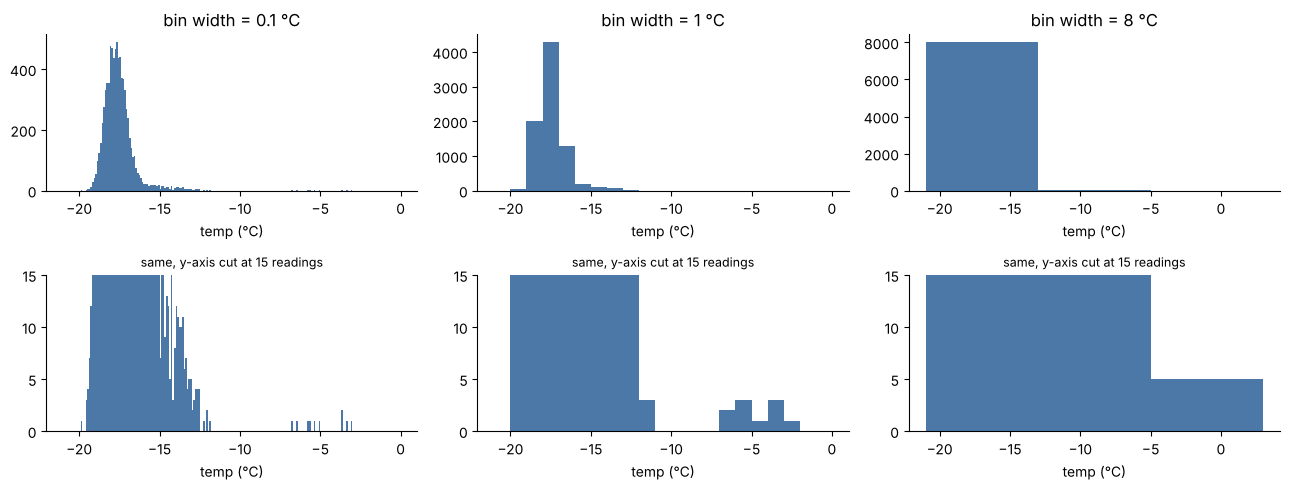

bin widths that show the warm tail: [0.1, 1] | readings above -8 °C: 10


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top: ax.set_ylim(0, top); ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else: ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout(); plt.show()

warm_tail_visible_bins = [0.1, 1]   # at 8 °C the warm readings merge into a bin of 31 with other values and are not separate
n_warm_readings = int((df["temp_c"] > -8).sum())   # readings warmer than -8 °C
print(f"bin widths that show the warm tail: {warm_tail_visible_bins} | readings above -8 °C: {n_warm_readings}")

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

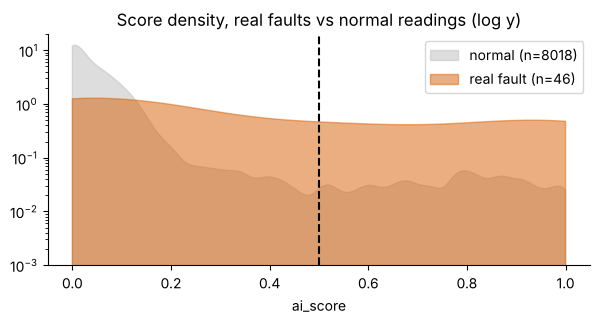

clean score cut-off exists: False


In [4]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False   # the two densities overlap: many faults score near 0 and many normal 2 am readings score high
print(f"clean score cut-off exists: {scores_separate_faults}")

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*Your answer:*

A histogram is a parameterised algorithm because the bin width and edges are choices that decide what you see: 0.1 °C bins look noisy, 1 °C bins show the warm readings as a separate tail, and 8 °C bins collapse everything into three bars (8,028 / 31 / 5 readings) where the 10 readings above −8 °C cannot be told apart from the other warm values. To the colleague I would say that "no anomalies in the 8 °C histogram" only describes that one setting: with 1 °C (or 0.1 °C) bins and a zoomed y-axis, 10 readings above −8 °C appear (all compressor trips), so re-draw with narrower bins and a zoomed axis before concluding anything.

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [5]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

z_max = np.max(np.abs((v - v.mean()) / np.std(v, ddof=1)))   # largest |z| using the sample SD
q1, q3 = np.percentile(v, [25, 75])
upper_fence = q3 + 1.5 * (q3 - q1)   # Tukey upper fence

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*Your answer:*

The z-score rule missed the trip because of *masking*: the extreme value inflates the window's own mean and SD, so its z is only 2.83, and with n = 10 the largest |z| any single outlier can reach is (n − 1)/√n = 2.85, which can never exceed 3. The IQR rule did not miss it because quartiles barely move for one extreme value (upper fence −15.58 °C), so the −3.6 °C trip lies far beyond it and is flagged.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [6]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = int((flag & real).sum())     # alerts that were real faults
FP = int((flag & ~real).sum())    # alerts on normal readings (false alarms)
FN = int((~flag & real).sum())    # real faults with no alert (missed)
TN = int((~flag & ~real).sum())   # normal readings with no alert

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [7]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
accuracy = (TP + TN) / (TP + FP + FN + TN)
flag_nothing_accuracy = (TN + FP) / (TP + FP + FN + TN)   # never alerting is right on every normal reading

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 99.4%


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

*Your answer:*

**Honest rewrite of statement 1:** *"ColdSense's 97.9% accuracy is misleading because real faults are only 0.57% of hours: a detector that never alerts would be 99.4% accurate. Its precision is 0.10 and its recall is 0.35."* In plain words for Ravi's technicians: about 9 out of every 10 call-outs are wasted (143 of 159 alerts were false alarms), and about 2 out of every 3 real faults are never flagged (30 of 46 missed).

---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

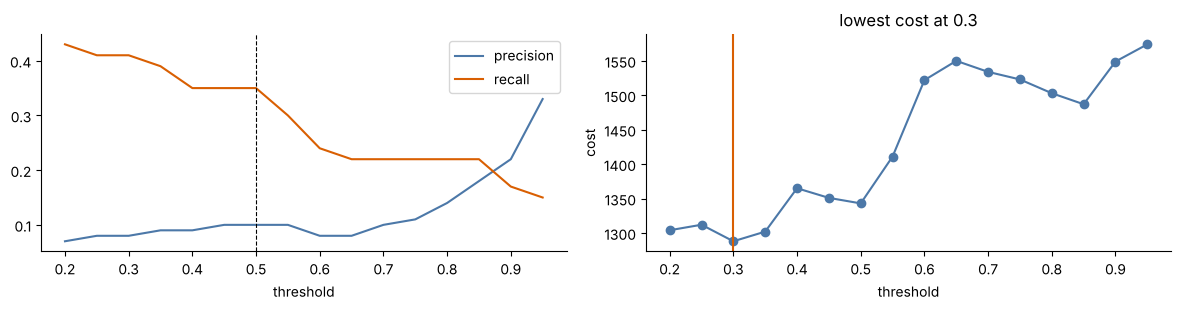

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [8]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep["FN"] + 1 * sweep["FP"]   # missed fault = 40, false call-out = 1
best_threshold = sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"]   # lowest-cost threshold

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

*Your answer:*

At the lowest-cost threshold (0.30, cost 1,288 vs 1,343 at the default 0.5, only about 4% better) recall is still just 0.41, because the missing faults are never scored high: all 25 "sensor frozen" fault hours score at most 0.096, and 5 of the 11 "defrost heater stuck" hours score below 0.4, so no threshold above 0.1 catches any frozen-sensor fault. A threshold only moves along the detector's own ranking, so it can trade false alarms for recall but cannot fix a blind spot; the cheaper threshold mainly adds more 2 am false alarms.

---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

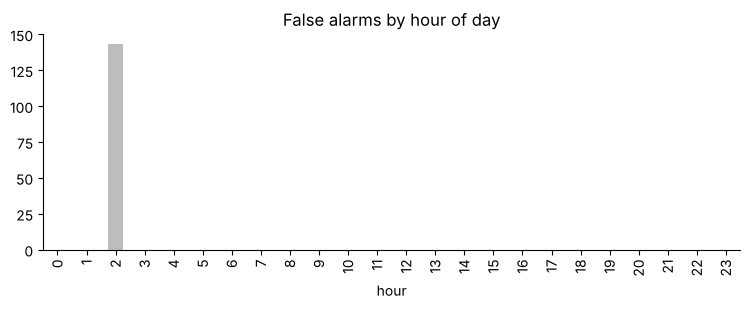

100% of false alarms happen at 2:00


In [9]:
fp_rows = df[flag & ~real]
fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_peak_hour = int(fp_rows.groupby("hour").size().idxmax())   # hour with the most false alarms
fp_share_at_peak = (fp_rows["hour"] == fp_peak_hour).mean()   # share of false alarms in that hour

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [10]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = caught.index[caught["caught"] == 0][0]   # fault type with zero alerts
anomaly_kind = 'collective'   # each flat-lined reading looks normal; the run of readings is abnormal
print(f"never caught: {never_caught_type} | anomaly kind: {anomaly_kind}")

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


never caught: sensor frozen | anomaly kind: collective


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [11]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"]   # distance from the usual value for this freezer and hour

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


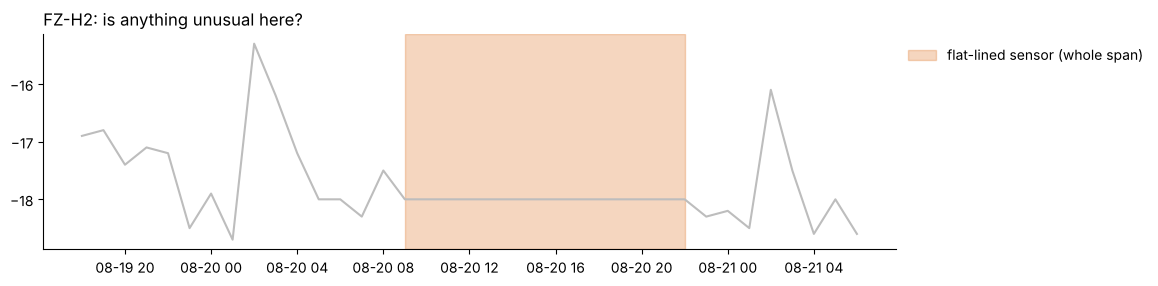

In [12]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01]   # rows where the 6-hour rolling SD is (almost) zero

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
    flat_h2 = flat[flat.freezer_id == "FZ-H2"]
    start = flat_h2.timestamp.min() - pd.Timedelta(hours=5)   # a 6-hour window ending at the first flat row began 5 h earlier
    ax.axvspan(start, flat_h2.timestamp.max(), color=ACCENT, alpha=.25, label="flat-lined sensor (whole span)")
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)

    ax.set_title("FZ-H2: is anything unusual here?", loc="left"); plt.show()
df = df.sort_values(["timestamp", "store_id"])

**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?
(b) Is vendor statement 5 true? Use the words *contextual anomaly* and say what a chart must show for a viewer to judge such an alert.
(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

*Your answer:*

**(a)** Vendor statement 2 is false as written. Rewrite: *"All 143 of ColdSense's false alarms (100%) occur at 02:00, during the automatic defrost cycle; none of the 46 confirmed fault hours falls at 2 am, and real faults happen between 07:00 and 22:00 (76% between 09:00 and 17:00)."* A night technician hired on the vendor's report would be sent out for a normal defrost warm-up about 3 times a night (143 false alarms over 42 days), wasting call-outs, while the real daytime faults, including the frozen sensors that never alert, would be missed.

**(b)** Statement 5 is not true. A reading of −14 °C is a *contextual anomaly* candidate: during the 02:00–04:00 defrost cycle it is normal (average temperature is −14.6 °C at 02:00 and −16.4 °C at 03:00), but at 14:00 the same value would be abnormal, so the value alone is not enough. To let a viewer judge such an alert, the chart must show the context: the expected band for that freezer and that hour (median ± MAD) behind the reading, with the defrost window marked. The context baseline in 6c gives 0 false alarms at 02:00 (vs 143 for ColdSense) and catches 3 defrost-heater faults ColdSense missed.

**(c)** Statement 4 is wrong: FZ-H2 had a confirmed "sensor frozen" fault for 14 hours on 20 August (09:00–22:00), reading a constant −18.0 °C; the lack of alerts is not the lack of a fault. A detector that scores readings one at a time can never catch it, because each flat reading is a perfectly normal −18 °C; what is abnormal is the *run* of readings with no variation at all, a collective anomaly that needs window-based features such as the rolling SD.

---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

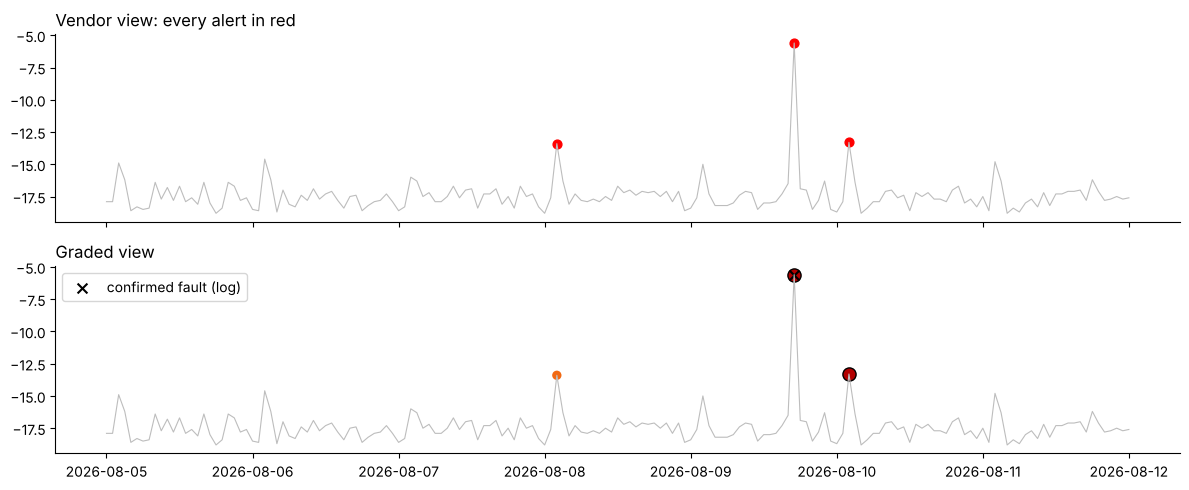

In [13]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    if score >= 0.90:    # strong: dark red, large, dark outline
        return ("#b30000", 90, "black")
    if score >= 0.70:    # moderate: orange, medium, no outline
        return ("#f16913", 45, "none")
    if score >= 0.50:    # subtle: hollow marker with a thin orange outline
        return ("white", 30, "#f16913")
    return (GREY, 8, "none")   # below 0.5: no emphasis, the data stays visible

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    a = week[week.ai_flag == 1]; ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40); ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]; ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left"); ax[1].set_title("Graded view", loc="left"); plt.tight_layout(); plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

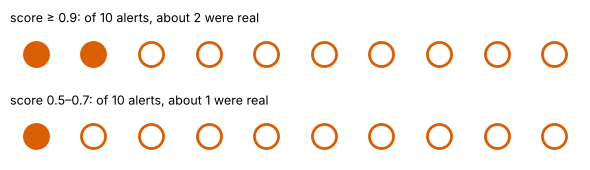

In [14]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

real_per_10_hi = int(round(band_hi["confirmed_fault"].mean() * 10))   # real faults per 10 alerts, score >= 0.9
real_per_10_lo = int(round(band_lo["confirmed_fault"].mean() * 10))   # real faults per 10 alerts, score 0.5-0.7

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

*Your answer:*

**(a)** Painting every alert bright red spends the strongest *salience* on 159 alerts of which 143 are false alarms, so red loses its meaning and technicians learn to ignore it. The frozen H2 sensor raises no alert at all: it is a calm, flat line at −18.0 °C with no red dot, so with attention pulled to the red dots, *inattentional blindness* makes an unmarked, unexpected pattern very easy to miss; emphasis should scale with confidence and flat-lines need their own highlight.

**(b)** *"Of 10 alerts with a score of 0.9 or more, only about 2 were real faults; of 10 alerts with a score of 0.5–0.7, about 1 was real. The score ranks alerts, but it is not a probability."*

---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [15]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)   # standard error of the baseline mean
z_sd = (new_reading - mu) / sd   # distance in standard deviations
z_se = (new_reading - mu) / se   # distance in standard errors (the vendor's calculation)

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = 'SD'   # a single reading is judged against the spread of readings, not the uncertainty of their mean
print(f"use {correct_z} for a single new reading; one-sided tail probability at z = {z_sd:.1f}: {stats.norm.sf(z_sd):.3f}")

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0
use SD for a single new reading; one-sided tail probability at z = 2.3: 0.010


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*Your answer:*

The SD (0.61 °C) describes how much individual 14:00 readings vary around their mean, so it is the right yardstick for a single new reading. The SE (0.094 °C = SD/√42) describes how precisely we know the *mean* and shrinks as the sample grows, so it makes any single reading look absurdly far away (15 "standard errors"). **Rewrite of statement 8:** *"−15.9 °C at 14:00 is about 2.3 standard deviations warmer than FZ-B1's usual 14:00 reading (−17.3 °C): unusual (roughly 1 in 100 normal readings would be this warm) and worth checking against the compressor power and maintenance log, but not a definite fault."*

---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [16]:
decisions = {
    1: "Correct",   # 97.9% accurate, so trustworthy
    2: "Reject",   # most faults happen around 2 am
    3: "Accept",   # all 10 compressor trips caught
    4: "Reject",   # FZ-H2 had no fault
    5: "Correct",   # -14 °C is abnormal at any time
    6: "Reject",   # score 0.92 = 92% chance
    7: "Reject",   # threshold 0.5 is best
    8: "Reject",   # 15 standard errors: definite fault
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Reject     5
Correct    2
Accept     1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*Your answer:*

**Anomaly review view for Ravi's team (instead of the red-dot dashboard):**

- **Main view:** one small time-series panel per freezer on a shared y-scale, with the reading as a line and ColdSense alerts drawn with graded emphasis (strong ≥ 0.9, moderate 0.7–0.9, subtle outline 0.5–0.7, none below 0.5) and confirmed faults from the log marked.
- **Context:** an expected band for the same freezer and hour (median ± MAD) behind the line, the 02:00–04:00 defrost window shaded, `door_opens` and `compressor_kw` aligned underneath, and a flat-line (rolling SD) indicator so frozen sensors get their own highlight.
- **Queue:** a ranked list of *candidates* (not conclusions) combining the ColdSense score and the context rule, grouped by freezer and by run of consecutive hours, sorted by confidence, with status new / confirmed / dismissed; defrost-window alerts that stay inside the expected band are collapsed.
- **Verification tools:** one click from a queue item to the raw readings, neighbouring freezers and past incidents for that freezer; confirm / dismiss with a reason; and a threshold control that shows the cost curve and expected call-outs per week.
- **Evaluation:** precision and recall computed from technicians' outcomes each week, false alarms by hour of day, a "missed faults" panel (logged faults that never alerted), and a periodic random audit of non-alerts.

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

*Your reflection:*

The 97.9% accuracy figure was the most convincing: it was a precise number, stated confidently, and it sounds like an exam grade. I would not have caught the problem without the maintenance log, because accuracy only looks bad once you compare it with the never-alert baseline (99.4%) and count the 143 false alarms and 30 missed faults.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

*Your reflection:*

The threshold is a business decision, not a technical setting, so the cold-chain lead (Ravi) should own it together with store operations and finance, since it trades spoiled stock against technician call-outs. The dashboard should show the cost curve, precision and recall at each threshold, the expected number of call-outs per week, and the assumed cost of a missed fault versus a false call-out (here 40 : 1) so that the assumptions are visible and can be changed.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

*Your reflection:*

Without a maintenance log, alerts that nobody inspected would have no label, so they would be counted as false alarms (understating precision) and faults that never alerted would never be discovered (overstating recall), because unknown faults do not appear as misses. The review workflow can reduce this by requiring technicians to record an outcome for every alert (confirmed, dismissed, not checked) and by auditing a random sample of non-alerts and low-score readings to estimate what is being missed.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

*Your reflection:*

Each alert should arrive as a card that shows its evidence, not a bare red dot: the score, the expected band for that hour, the defrost-window label and how many past alerts of this kind turned out to be real (for example "0 of 143 alerts at 02:00 were real"). The technician would then have to confirm or dismiss with a reason, which makes them check the alert instead of simply obeying or ignoring it.